# Lung Disease Detection and Differentiation: EfficientNetV2-L

Part of my Final Year Project (BS Computer Science, The Islamia University of Bahawalpur, 2022–2026), *A Novel Deep Learning-Based System for Identification and Differentiation of Lung Diseases*.

This notebook trains and evaluates **EfficientNetV2-L** on my 7-class chest X-ray dataset (42,682 images): atelectasis, bacterial pneumonia, COVID-19, emphysema, normal, tuberculosis and viral pneumonia.

During the project I trained and compared seven architectures. On my supervisor's advice the final report focuses on the two strongest, EfficientNetV2-L (this notebook) and ConvNeXt-Large (`convnext_large_lung_xray.ipynb`). The repository README explains the full story.


**What the first code cell does** (it was run once, top to bottom, as a single Kaggle job):

1. **Config and seeding.** 7 classes, 224×224 input, batch size 32, 25 epochs, AdamW (lr 1e-4, weight decay 1e-2), seed 42.
2. **Data loading.** All images are read with `ImageFolder` and split 80/10/10 into train / validation / test (seeded `random_split`). Training augmentation: random horizontal flip, ±15° rotation, 10% translation, brightness/contrast jitter, then ImageNet normalisation.
3. **Class imbalance.** A `WeightedRandomSampler` with inverse-frequency weights, so rare classes (atelectasis, emphysema) are seen as often as `normal` during training.
4. **Model.** ImageNet-pretrained `efficientnet_v2_l` from torchvision, with the last linear layer (`classifier[1]`) replaced by a 7-class head.
5. **Training.** Mixed precision (`torch.amp`), `nn.DataParallel` across 2× Tesla T4, cross-entropy loss. The weights with the best validation accuracy are kept.
6. **Evaluation.** Classification report and confusion matrix on the held-out test split (4,269 images).
7. **Explainability.** Grad-CAM hooked on the last feature block (`features[-1]`), shown for one test image per class.

The second code cell is a small single-image inference helper (see the note above it).

Run on Kaggle (2× Tesla T4, Python 3.11) on 24 December 2025. Training took about 323 minutes.

> The `data_dir` path points to my Kaggle dataset, which is not public. To run this notebook, attach a dataset with the same 7 class folders and change `CONFIG['data_dir']`.

Initializing Data Loaders (80% Train, 10% Val, 10% Test)...
Loading data from: /kaggle/input/lung-diseases-x-ray-images/Lung Dataset_v2/Lung Dataset
Total Images: 42682. Splitting: Train=34145, Val=4268, Test=4269
Calculating weights for WeightedRandomSampler...
Class Counts in Training Set (before balancing): Counter({4: 11142, 6: 8114, 1: 4603, 2: 3592, 5: 2582, 3: 2059, 0: 2053})
Classes: ['atelectasis', 'bacterial_pneumonia', 'covid19', 'emphysema', 'normal', 'tuberculosis', 'viral_pneumonia']
Loading EfficientNetV2-L...


Downloading: "https://download.pytorch.org/models/efficientnet_v2_l-59c71312.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_l-59c71312.pth
100%|██████████| 455M/455M [00:02<00:00, 190MB/s]


Using 2 GPUs!
Starting Training...
Epoch 1/25
----------
train Loss: 0.4614 Acc: 0.8089
val Loss: 0.3671 Acc: 0.8233
Epoch 2/25
----------
train Loss: 0.2910 Acc: 0.8735
val Loss: 0.3702 Acc: 0.8397
Epoch 3/25
----------
train Loss: 0.2497 Acc: 0.8871
val Loss: 0.3209 Acc: 0.8618
Epoch 4/25
----------
train Loss: 0.2209 Acc: 0.9000
val Loss: 0.2598 Acc: 0.8732
Epoch 5/25
----------
train Loss: 0.2038 Acc: 0.9056
val Loss: 0.3021 Acc: 0.8655
Epoch 6/25
----------
train Loss: 0.1879 Acc: 0.9140
val Loss: 0.2864 Acc: 0.8768
Epoch 7/25
----------
train Loss: 0.1764 Acc: 0.9172
val Loss: 0.2701 Acc: 0.8828
Epoch 8/25
----------
train Loss: 0.1608 Acc: 0.9263
val Loss: 0.2835 Acc: 0.8714
Epoch 9/25
----------
train Loss: 0.1607 Acc: 0.9241
val Loss: 0.3056 Acc: 0.8639
Epoch 10/25
----------
train Loss: 0.1481 Acc: 0.9305
val Loss: 0.2531 Acc: 0.8805
Epoch 11/25
----------
train Loss: 0.1429 Acc: 0.9335
val Loss: 0.2237 Acc: 0.8920
Epoch 12/25
----------
train Loss: 0.1345 Acc: 0.9360
val Los

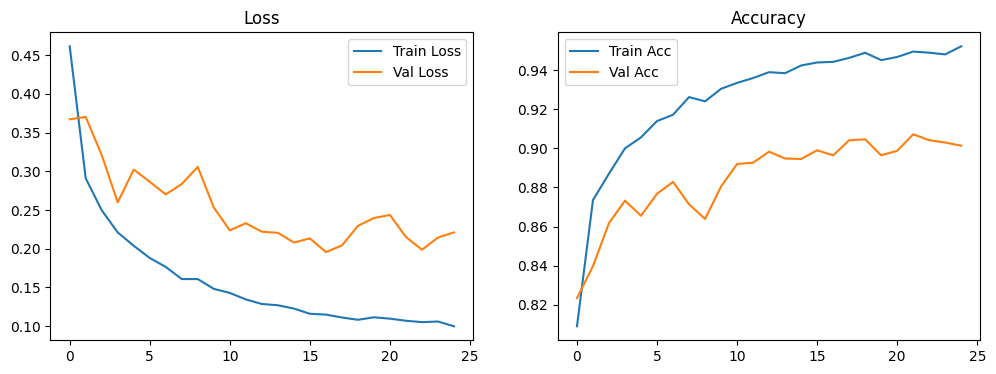


Generating Evaluation Metrics on the dedicated Test Set...

Classification Report (Test Set):
                     precision    recall  f1-score   support

        atelectasis       0.99      1.00      1.00       259
bacterial_pneumonia       0.64      0.91      0.75       598
            covid19       0.96      0.96      0.96       441
          emphysema       0.96      0.99      0.98       248
             normal       0.99      0.98      0.99      1407
       tuberculosis       0.99      0.98      0.99       302
    viral_pneumonia       0.92      0.70      0.79      1014

           accuracy                           0.90      4269
          macro avg       0.92      0.93      0.92      4269
       weighted avg       0.92      0.90      0.90      4269



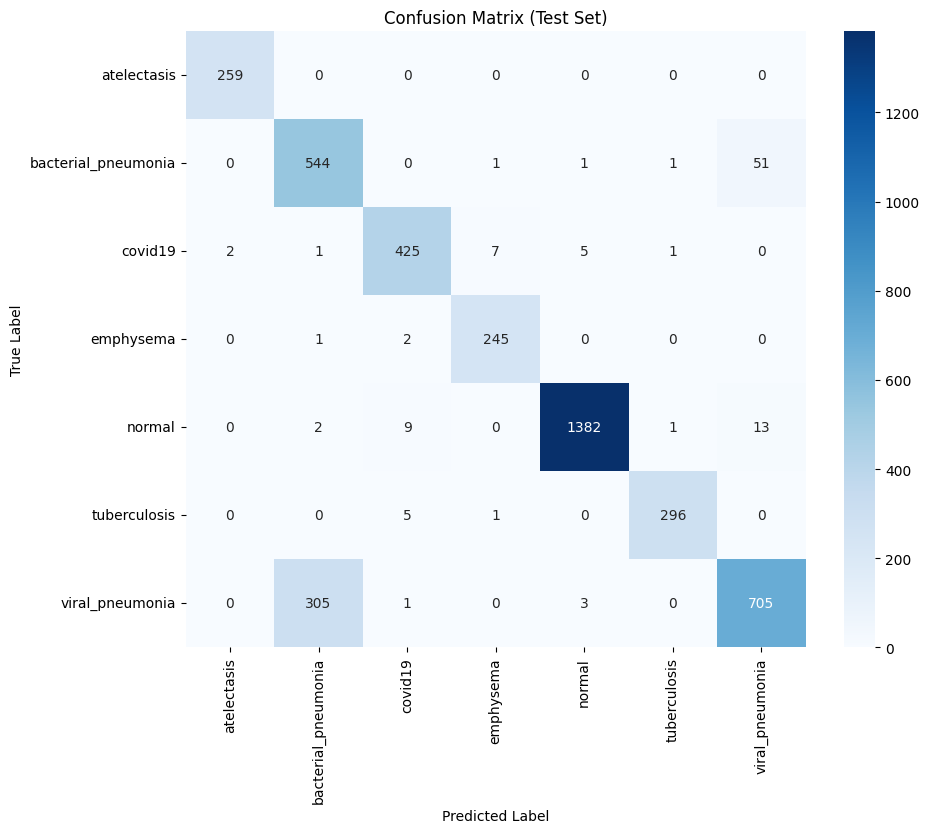


Generating Grad-CAM visualizations for one image per class...


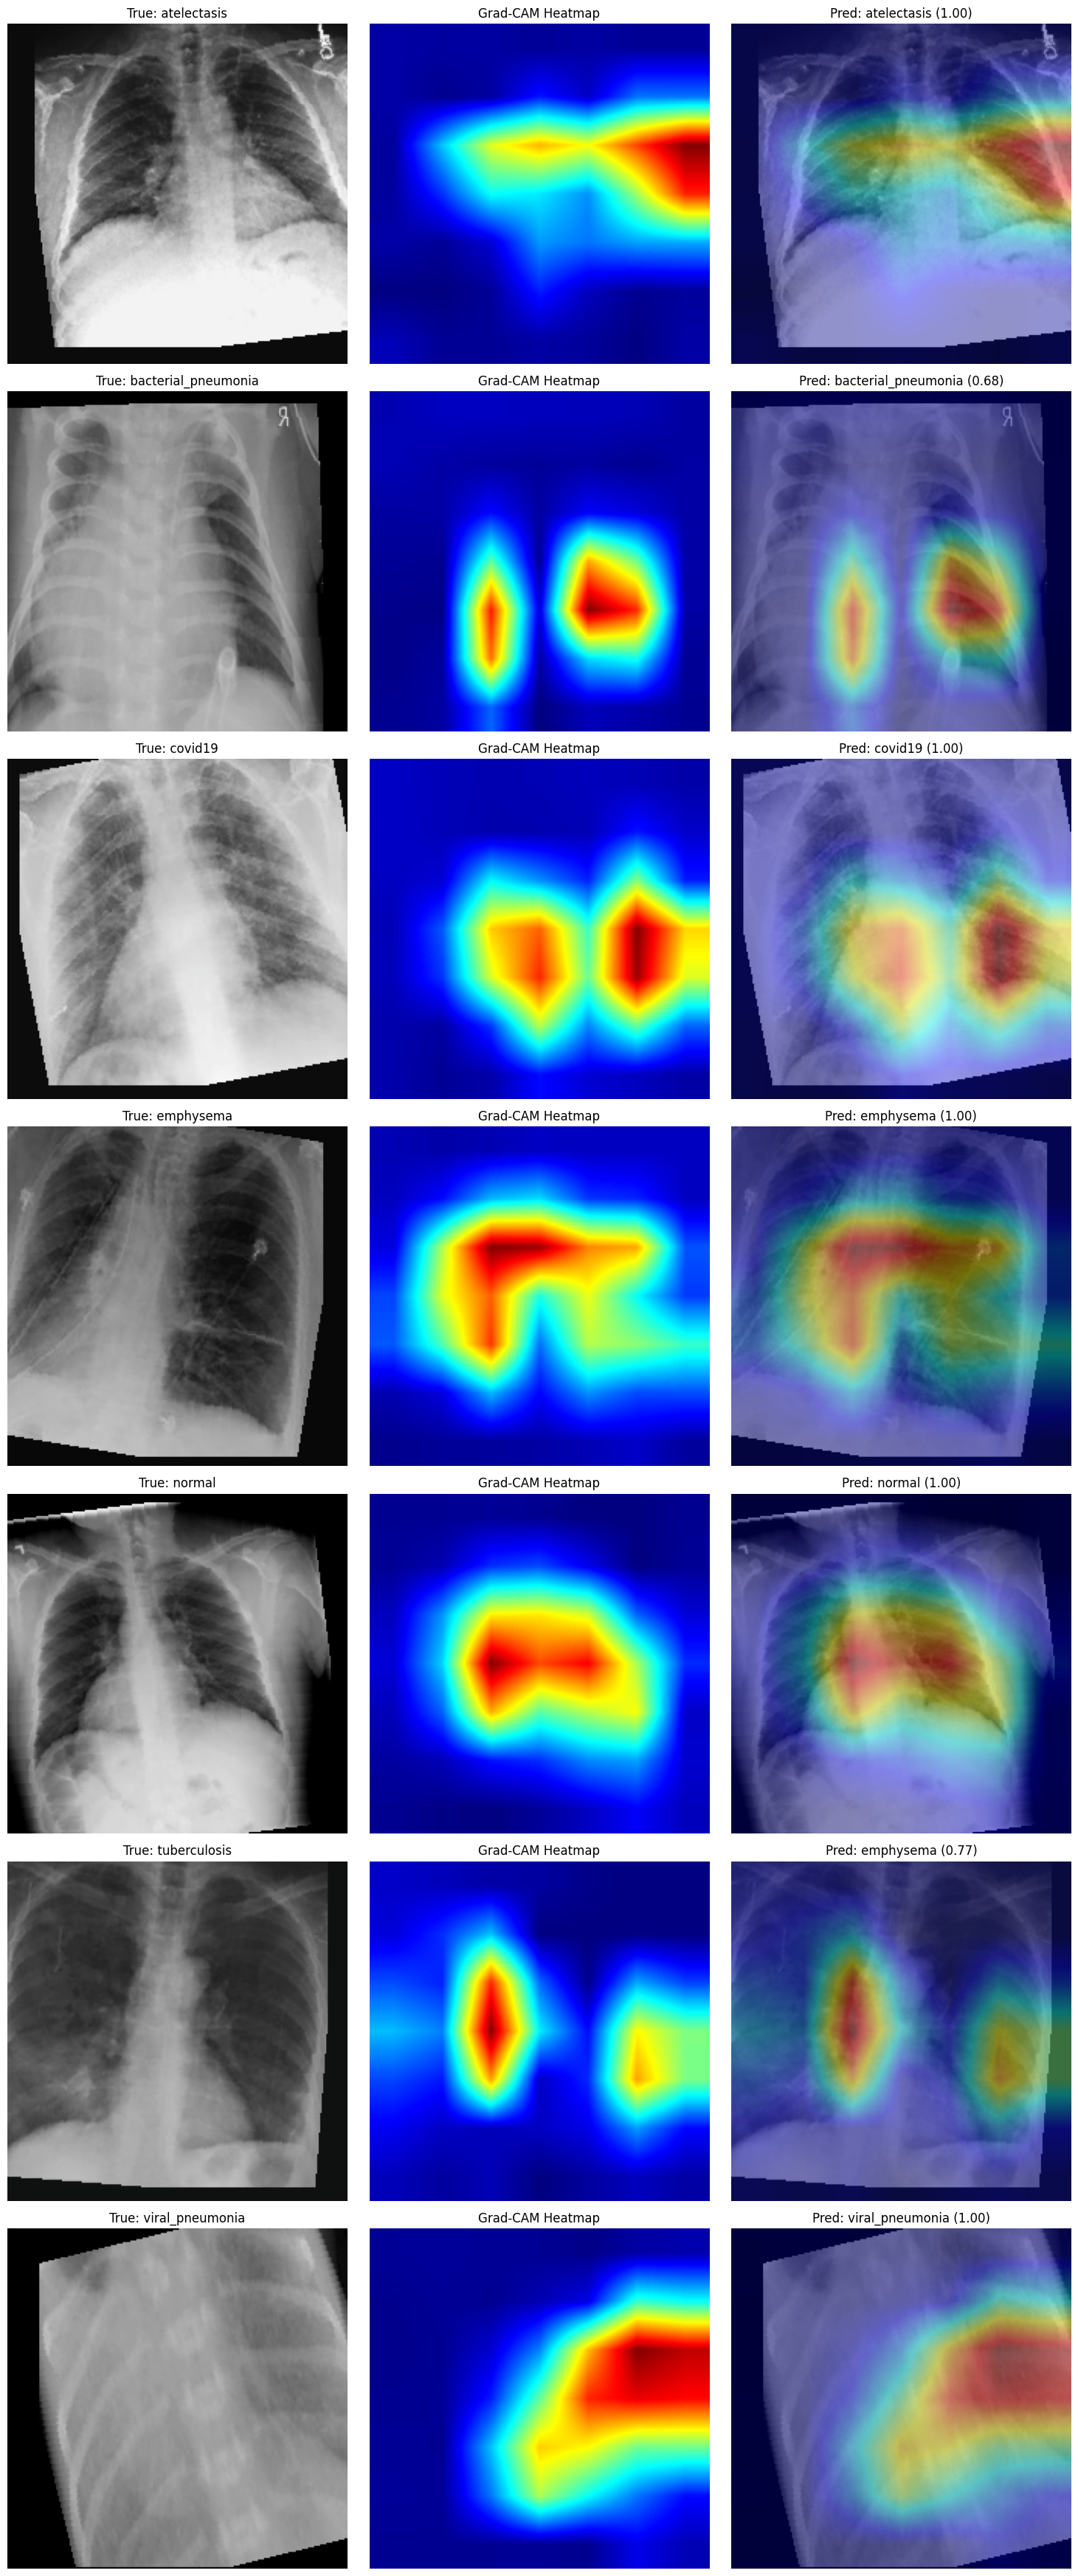

In [ ]:
import os
import random
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import datasets, models, transforms

# CONFIGURATION
CONFIG = {
    'data_dir': "/kaggle/input/lung-diseases-x-ray-images/Lung Dataset_v2/Lung Dataset",
    'num_classes': 7,
    'classes': ['atelectasis', 'bacterial_pneumonia', 'covid19', 
                'emphysema', 'normal', 'tuberculosis', 'viral_pneumonia'],
    'batch_size': 32, 
    'num_epochs': 25,
    'learning_rate': 1e-4,
    'device': torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    'img_size': 224,
    'seed': 42,
    'train_ratio': 0.8,
    'val_ratio': 0.1,
    'test_ratio': 0.1,
}

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True

set_seed(CONFIG['seed'])

# 1. DATA TRANSFORMATION & LOADING (80/10/10 Split & Imbalance)

def get_data_loaders(data_dir, config):
    print(f"Loading data from: {data_dir}")
    
    # Define Transforms
    train_transforms = transforms.Compose([
        transforms.Resize((config['img_size'], config['img_size'])),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Validation and Test transforms (only resize and normalize)
    val_test_transforms = transforms.Compose([
        transforms.Resize((config['img_size'], config['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Load ALL images using ImageFolder (flat structure)
    full_dataset = datasets.ImageFolder(data_dir, transform=val_test_transforms)
    
    # Determine split sizes
    total_size = len(full_dataset)
    train_size = int(config['train_ratio'] * total_size)
    val_size = int(config['val_ratio'] * total_size)
    test_size = total_size - train_size - val_size
    
    # Split the dataset 80/10/10
    print(f"Total Images: {total_size}. Splitting: Train={train_size}, Val={val_size}, Test={test_size}")
    train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
        full_dataset, 
        [train_size, val_size, test_size],
        generator=torch.Generator().manual_seed(config['seed'])
    )
    
    # Apply the aggressive augmentation transform ONLY to the training set
    train_dataset.dataset.transform = train_transforms
    
    # ADDRESSING CLASS IMBALANCE IN TRAINING SET
    print("Calculating weights for WeightedRandomSampler...")
    train_targets = [full_dataset.targets[i] for i in train_dataset.indices]
    class_counts = Counter(train_targets)
    
    # Calculate weight per class (inverse frequency)
    class_weights = {cls: 1.0 / count for cls, count in class_counts.items()}
    
    # Assign a weight to every sample in the training split
    sample_weights = [class_weights[t] for t in train_targets]
    
    # Create WeightedRandomSampler
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_dataset),
        replacement=True
    )
    print(f"Class Counts in Training Set (before balancing): {class_counts}")

    # DataLoaders
    train_loader = DataLoader(
        train_dataset, 
        batch_size=config['batch_size'], 
        sampler=sampler,
        num_workers=4, 
        pin_memory=True
    )
    
    val_loader = DataLoader(
        val_dataset, 
        batch_size=config['batch_size'], 
        shuffle=False, 
        num_workers=4, 
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset, 
        batch_size=1,
        shuffle=False, 
        num_workers=4, 
        pin_memory=True
    )

    return train_loader, val_loader, test_loader, full_dataset.classes

# 2. MODEL DEFINITION (EfficientNetV2-L)

def get_model(num_classes):
    print("Loading EfficientNetV2-L...")
    # Load pre-trained EfficientNetV2-L
    model = models.efficientnet_v2_l(weights=models.EfficientNet_V2_L_Weights.IMAGENET1K_V1)
    
    # Modify the classifier head
    # EfficientNet Classifier structure: Sequential(Dropout, Linear)
    # We access index [1] for the Linear layer
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    
    # Move to GPU
    model = model.to(CONFIG['device'])
    
    # Enable DataParallel for T4x2 usage
    if torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs!")
        model = nn.DataParallel(model)
        
    return model

# 3. TRAINING LOOP (With Mixed Precision)

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    since = time.time()
    
    # Use generalized AMP scaler
    scaler = torch.amp.GradScaler('cuda') 
    
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data
            for inputs, labels in dataloader:
                inputs = inputs.to(CONFIG['device'])
                labels = labels.to(CONFIG['device'])

                optimizer.zero_grad()

                # Forward
                with torch.set_grad_enabled(phase == 'train'):
                    # Use generalized AMP autocast
                    with torch.amp.autocast('cuda'): 
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                    # Backward + optimize only if in training phase
                    if phase == 'train':
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
            
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            # Deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Val Acc: {best_acc:.4f}')

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model, history

# 4. GRAD-CAM IMPLEMENTATION

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Hooks
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, class_idx=None):
        # 1. Forward pass
        output = self.model(x)
        if class_idx is None:
            class_idx = torch.argmax(output).item()

        # 2. Backward pass for specific class
        self.model.zero_grad()
        # Ensure we access the correct output element if batch size > 1
        class_loss = output[0, class_idx] 
        class_loss.backward()

        # 3. Get gradients and activations (pooled gradients)
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()
        
        # 4. Weight the channels by gradients
        for i in range(activations.shape[1]):
            activations[:, i, :, :] *= pooled_gradients[i]
            
        # 5. Average the channels of the activations (heatmap generation)
        heatmap = torch.mean(activations, dim=1).squeeze()
        heatmap = F.relu(heatmap)
        
        # Handle division by zero
        max_val = torch.max(heatmap)
        if max_val > 0:
             heatmap /= max_val
        
        return heatmap.cpu().numpy()

# 5. VISUALIZATION & REPORTS

def evaluate_and_visualize(model, test_loader, class_names):
    model.eval()
    
    # A. Classification Report & Confusion Matrix (on Test Set)
    all_preds = []
    all_labels = []
    
    print("\nGenerating Evaluation Metrics on the dedicated Test Set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(CONFIG['device'])
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    print("\nClassification Report (Test Set):")
    print(classification_report(all_labels, all_preds, target_names=class_names))
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix (Test Set)")
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

    # B. Grad-CAM Visualization for 7 Specific Images
    print("\nGenerating Grad-CAM visualizations for one image per class...")
    
    # Handle DataParallel unwrapping for hook registration
    if isinstance(model, nn.DataParallel):
        raw_model = model.module
    else:
        raw_model = model
        
    # Hook into the last feature block of EfficientNetV2 for Grad-CAM
    # EfficientNetV2 uses a 'features' sequential block. The last element [-1] is the final conv stage.
    target_layer = raw_model.features[-1] 
    grad_cam = GradCAM(raw_model, target_layer)
    
    # We will grab the first image of each class encountered in the test_loader
    images_to_visualize = {}
    
    # Iterate through the test set to find one image of each true class
    for i, (input_tensor, true_label) in enumerate(test_loader):
        true_class_name = class_names[true_label.item()]
        if true_class_name not in images_to_visualize:
            # We need the input tensor (normalized) and the true index for visualization
            images_to_visualize[true_class_name] = (input_tensor, true_label.item(), test_loader.dataset.dataset.imgs[test_loader.dataset.indices[i]][0])
            if len(images_to_visualize) == CONFIG['num_classes']:
                break
    
    fig, axes = plt.subplots(CONFIG['num_classes'], 3, figsize=(15, 5 * CONFIG['num_classes']))
    
    # Denormalization to visualize the original image correctly
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )

    for i, cls_name in enumerate(class_names):
        if cls_name not in images_to_visualize:
            print(f"Warning: Could not find an image for class {cls_name} in the test set for visualization.")
            continue

        input_tensor, true_idx, _ = images_to_visualize[cls_name]
        input_tensor = input_tensor.to(CONFIG['device'])
        
        # Get Prediction
        output = model(input_tensor)
        prob = F.softmax(output, dim=1)
        pred_idx = torch.argmax(prob).item()
        pred_class = class_names[pred_idx]
        confidence = prob[0][pred_idx].item()
        
        # Generate Heatmap
        heatmap = grad_cam(input_tensor, class_idx=pred_idx)
        
        # Denormalize tensor for visualization
        img_denorm = inv_normalize(input_tensor.squeeze(0).cpu()).permute(1, 2, 0).numpy()
        # Clamp values to [0, 1]
        img_denorm = np.clip(img_denorm, 0, 1)

        # Resize heatmap to image size (224x224)
        heatmap = cv2.resize(heatmap, (CONFIG['img_size'], CONFIG['img_size']))
        heatmap = np.uint8(255 * heatmap)
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        
        # Convert RGB to BGR for OpenCV processing, then overlay
        img_bgr = cv2.cvtColor(np.uint8(255 * img_denorm), cv2.COLOR_RGB2BGR)
        superimposed = cv2.addWeighted(img_bgr, 0.6, heatmap, 0.4, 0)
        superimposed = cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB)
        
        # Plotting
        axes[i, 0].imshow(img_denorm)
        axes[i, 0].set_title(f"True: {cls_name}")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title("Grad-CAM Heatmap")
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(superimposed)
        axes[i, 2].set_title(f"Pred: {pred_class} ({confidence:.2f})")
        axes[i, 2].axis('off')
        
    plt.tight_layout()
    plt.savefig('disease_localization_results.png')
    plt.show()

# MAIN EXECUTION

if __name__ == '__main__':
    # 1. Prepare Data
    print("Initializing Data Loaders (80% Train, 10% Val, 10% Test)...")
    try:
        # Use the corrected function signature
        train_loader, val_loader, test_loader, class_names = get_data_loaders(CONFIG['data_dir'], CONFIG)
        print(f"Classes: {class_names}")

        # 2. Setup Model
        model = get_model(CONFIG['num_classes'])
        
        # 3. Setup Training Components
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-2)
        
        # 4. Train
        print("Starting Training...")
        model, history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=CONFIG['num_epochs'])
        
        # 5. Save Model
        torch.save(model.state_dict(), 'efficientnet_v2_chest_xray.pth')
        print("Model saved.")
        
        # 6. Plot Training Curves
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(history['train_loss'], label='Train Loss')
        plt.plot(history['val_loss'], label='Val Loss')
        plt.legend()
        plt.title('Loss')
        
        plt.subplot(1, 2, 2)
        plt.plot(history['train_acc'], label='Train Acc')
        plt.plot(history['val_acc'], label='Val Acc')
        plt.legend()
        plt.title('Accuracy')
        plt.savefig('training_curves.png')
        plt.show()

        # 7. Final Evaluation & Visualization
        evaluate_and_visualize(model, test_loader, class_names)

    except FileNotFoundError as e:
        print(f"ERROR: Data directory issue. Please check the path and folder structure.")
        print(f"Details: {e}")
    except Exception as e:
        print(f"An unexpected error occurred: {e}")

## Results of this run

All numbers below are copied from the output above. Nothing was re-run.

| Metric | EfficientNetV2-L |
|---|---|
| Best validation accuracy | **90.72%** (epoch 22) |
| Test accuracy | **90.33%** (3,856 / 4,269) |
| Test macro F1 | 0.92 |
| Test weighted F1 | 0.90 |
| Training time (2× T4) | 323 min |

**Reading the confusion matrix:** five of the seven classes reach F1 ≥ 0.96. Almost all the errors come from one pair: 305 viral pneumonia images predicted as bacterial and 51 the other way round. That is 356 of the model's 413 test errors (86%). Telling viral from bacterial pneumonia on a chest X-ray alone is hard, so this is where the remaining work is.

EfficientNetV2-L is the slightly stronger of the two final models (90.33% vs 90.04% test accuracy for ConvNeXt-Large), at the cost of about 70 more minutes of training.

> **Note on evaluation:** in `get_data_loaders`, the training transform is assigned to the shared underlying `ImageFolder` (`train_dataset.dataset.transform = ...`). Because `random_split` returns views of the same dataset, the validation and test images also pass through the random augmentation. You can see this in the rotated and shifted Grad-CAM inputs above. The test numbers are therefore measured on augmented test images. The repository README discusses this under *Limitations*.

## Single-image inference with Grad-CAM

A helper for predicting one X-ray and showing its Grad-CAM heatmap next to the original. It reuses `get_model` and `GradCAM` from the cell above, so run that cell first, then set `test_image_path` to an image file.

This cell was not executed in the saved run, which is why it has no output. An example of its output on a hospital X-ray is in the final report (section 4.4, *Results for BVH Dataset*).

In [ ]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F

# CONFIGURATION
CONFIG = {
    'img_size': 224,
    'num_classes': 7,
    'classes': ['atelectasis', 'bacterial_pneumonia', 'covid19', 
                'emphysema', 'normal', 'tuberculosis', 'viral_pneumonia'],
    'device': torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

def predict_and_visualize(image_path, model_path=None):
    """
    Loads an image, predicts the class using the trained model, 
    and visualizes the Grad-CAM heatmap.
    """
    print(f"Processing: {image_path}")
    
    # 1. Define Transforms (Must match Validation/Test transforms)
    inference_transform = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    # 2. Load Image
    try:
        orig_image = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Error loading image: {e}")
        return

    img_tensor = inference_transform(orig_image).unsqueeze(0).to(CONFIG['device'])
    
    # 3. Load Model
    # We re-initialize the model structure using your existing get_model function
    try:
        model = get_model(CONFIG['num_classes'])
    except NameError:
        print("Error: 'get_model' function not found. Please run the cell defining the model first.")
        return
    
    # Load weights
    if model_path is None:
        # Auto-detect the likely saved filename based on architecture
        if 'efficientnet' in str(type(model)).lower(): filename = 'efficientnet_v2_chest_xray.pth'
        elif 'convnext' in str(type(model)).lower(): filename = 'convnext_chest_xray.pth'
        else: filename = 'best_model_checkpoint.pth'
    else:
        filename = model_path
        
    print(f"Loading weights from: {filename}")
    try:
        # Handle DataParallel loading if weights were saved with 'module.' prefix
        state_dict = torch.load(filename, map_location=CONFIG['device'])
        
        # If the model was saved as DataParallel but we are loading to single GPU (or vice versa), 
        # we might need to adjust keys. 
        if list(state_dict.keys())[0].startswith('module.'):
            # Create a new dict without 'module.' prefix
            from collections import OrderedDict
            new_state_dict = OrderedDict()
            for k, v in state_dict.items():
                name = k[7:] # remove `module.`
                new_state_dict[name] = v
            state_dict = new_state_dict
            
        model.load_state_dict(state_dict, strict=False)
    except FileNotFoundError:
        print("Weight file not found! Using current model in memory if available.")
    
    model.eval()
    
    # 4. Auto-Detect Grad-CAM Target Layer
    # This block figures out which model architecture you are using
    if isinstance(model, torch.nn.DataParallel):
        raw_model = model.module
    else:
        raw_model = model

    # SMART DETECTION LOGIC (Simplified for CNNs only)
    target_layer = None
    if hasattr(raw_model, 'features'):
        # This standard block works for both ConvNeXt and EfficientNetV2
        print("Architecture detected: CNN (Hooking last feature block)")
        # In torchvision, both ConvNeXt and EfficientNet store the main layers in 'features'
        # We hook the last block [-1] to get the final spatial map before pooling
        target_layer = raw_model.features[-1]
    else:
        print("Could not auto-detect target layer. Grad-CAM might fail.")

    # 5. Prediction
    # Ensure GradCAM class is defined
    try:
        grad_cam = GradCAM(raw_model, target_layer)
    except NameError:
         print("Error: 'GradCAM' class not found. Please run the cell defining GradCAM first.")
         return

    output = model(img_tensor)
    probs = F.softmax(output, dim=1)
    pred_idx = torch.argmax(probs).item()
    pred_class = CONFIG['classes'][pred_idx]
    confidence = probs[0][pred_idx].item()
    
    # 6. Generate Heatmap
    heatmap = grad_cam(img_tensor, class_idx=pred_idx)
    
    # 7. Visualization
    # Inverse Normalization for display
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_denorm = inv_normalize(img_tensor.squeeze(0).cpu()).permute(1, 2, 0).numpy()
    img_denorm = np.clip(img_denorm, 0, 1)

    # Resize heatmap
    heatmap = cv2.resize(heatmap, (CONFIG['img_size'], CONFIG['img_size']))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    
    # Overlay
    img_bgr = cv2.cvtColor(np.uint8(255 * img_denorm), cv2.COLOR_RGB2BGR)
    superimposed = cv2.addWeighted(img_bgr, 0.6, heatmap, 0.4, 0)
    superimposed = cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB)
    
    # Plot
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    
    ax[0].imshow(img_denorm)
    ax[0].set_title("Original Input")
    ax[0].axis('off')
    
    ax[1].imshow(cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Grad-CAM Heatmap")
    ax[1].axis('off')
    
    ax[2].imshow(superimposed)
    ax[2].set_title(f"Prediction: {pred_class}\nConfidence: {confidence*100:.2f}%")
    ax[2].axis('off')
    
    plt.show()

# Change the path below to any image in your dataset or a new upload 
test_image_path = "image_path_here"

# Run the function
predict_and_visualize(test_image_path)